In [7]:
# ========== 1. Imports ==========
import os
import torch
import torch.nn as nn
from torchvision import transforms, datasets
from torch.utils.data import DataLoader, random_split
from sklearn.metrics import classification_report, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import timm
import json
from tqdm import tqdm


In [8]:
# ========== 2. Device Setup ==========
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f" Using device: {device}")


 Using device: cuda


In [9]:
# ========== 3. Paths ==========
train_dir = r"C:\\Users\\STUDENT\\Downloads\\brainmri\\archive\\Training_256x256"
test_dir  = r"C:\\Users\\STUDENT\\Downloads\\brainmri\\archive\\Testing_256x256"


In [10]:
# ========== 4. Transformations ==========
train_transform = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

test_transform = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])


In [11]:
# ========== 5. Dataset & Dataloaders ==========
full_dataset = datasets.ImageFolder(train_dir, transform=train_transform)
train_size = int(0.7 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])
val_dataset.dataset.transform = test_transform

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)

In [12]:
# ========== 6. Model Definition ==========
model = timm.create_model('inception_v4', pretrained=True, num_classes=4, drop_rate=0.4)
model.to(device)


InceptionV4(
  (features): Sequential(
    (0): ConvNormAct(
      (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), bias=False)
      (bn): BatchNormAct2d(
        32, eps=0.001, momentum=0.1, affine=True, track_running_stats=True
        (drop): Identity()
        (act): ReLU(inplace=True)
      )
    )
    (1): ConvNormAct(
      (conv): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), bias=False)
      (bn): BatchNormAct2d(
        32, eps=0.001, momentum=0.1, affine=True, track_running_stats=True
        (drop): Identity()
        (act): ReLU(inplace=True)
      )
    )
    (2): ConvNormAct(
      (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn): BatchNormAct2d(
        64, eps=0.001, momentum=0.1, affine=True, track_running_stats=True
        (drop): Identity()
        (act): ReLU(inplace=True)
      )
    )
    (3): Mixed3a(
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
      (c

In [13]:
# ========== 7. Loss, Optimizer, Scheduler ==========
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)

In [15]:
# ========== 8. Training Loop ==========
num_epochs = 10
best_val_acc = 0
patience = 3
counter = 0
best_model = model.state_dict()

train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []
all_preds, all_labels = [], []

print("\n Starting Training Loop...\n")
for epoch in range(num_epochs):
    model.train()
    correct, total, train_loss = 0, 0, 0
    for imgs, labels in tqdm(train_loader, desc=f"Epoch {epoch+1} [Train]", leave=False):
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
        train_loss += loss.item()

    train_acc = 100 * correct / total
    train_losses.append(train_loss / len(train_loader))
    train_accuracies.append(train_acc)

    model.eval()
    correct, total, val_loss = 0, 0, 0
    fold_preds, fold_labels = [], []
    with torch.no_grad():
        for imgs, labels in tqdm(val_loader, desc=f"Epoch {epoch+1} [Val]", leave=False):
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            _, preds = torch.max(outputs, 1)

            correct += (preds == labels).sum().item()
            total += labels.size(0)
            val_loss += loss.item()

            fold_preds.extend(preds.cpu().numpy())
            fold_labels.extend(labels.cpu().numpy())

    val_acc = 100 * correct / total
    val_losses.append(val_loss / len(val_loader))
    val_accuracies.append(val_acc)

    print(f"Epoch {epoch+1}:  Train Acc = {train_acc:.2f}%,  Val Acc = {val_acc:.2f}%")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_model = model.state_dict()
        all_preds = fold_preds
        all_labels = fold_labels
        counter = 0
    else:
        counter += 1
        if counter >= patience:
            print(" Early stopping triggered.")
            break

    scheduler.step()



 Starting Training Loop...



Epoch 1:  Train Acc = 92.07%,  Val Acc = 96.97%


Epoch 2:  Train Acc = 97.30%,  Val Acc = 96.91%


Epoch 3:  Train Acc = 98.75%,  Val Acc = 97.84%


Epoch 4:  Train Acc = 99.00%,  Val Acc = 98.37%


...

Epoch 6:  Train Acc = 99.37%,  Val Acc = 98.37%


Epoch 7:  Train Acc = 99.77%,  Val Acc = 98.54%


Epoch 8:  Train Acc = 99.82%,  Val Acc = 98.66%


Epoch 9:  Train Acc = 99.90%,  Val Acc = 98.77%


Epoch 10:  Train Acc = 99.92%,  Val Acc = 98.60%


In [16]:
# ========== 9. Save Best Model ==========
model.load_state_dict(best_model)

<All keys matched successfully>

In [17]:
# ========== 10. Evaluation Metrics ==========
precision = precision_score(all_labels, all_preds, average='macro')
recall = recall_score(all_labels, all_preds, average='macro')
f1 = f1_score(all_labels, all_preds, average='macro')
params = sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6

metrics = {
    "mode": "without_cv",
    "accuracy": round(best_val_acc, 2),
    "precision": round(precision * 100, 2),
    "recall": round(recall * 100, 2),
    "f1_score": round(f1 * 100, 2),
    "parameters_million": round(params, 2)
}

with open("metrics_inceptionv4_without_cv.json", "w") as f:
    json.dump(metrics, f, indent=4)


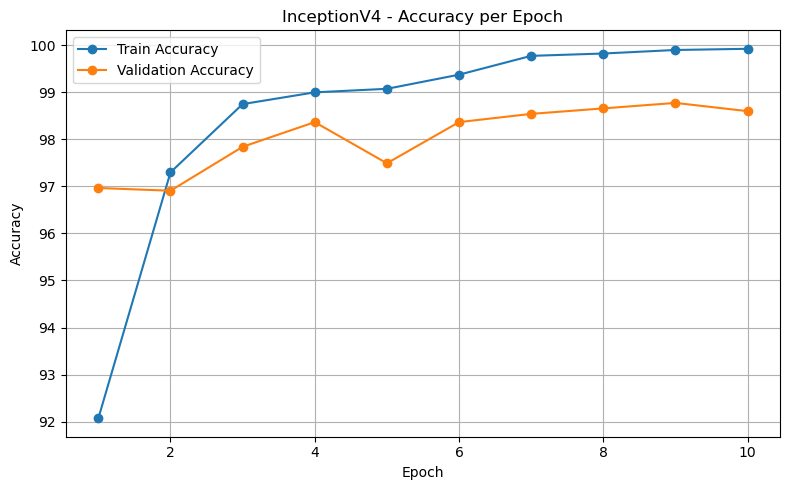

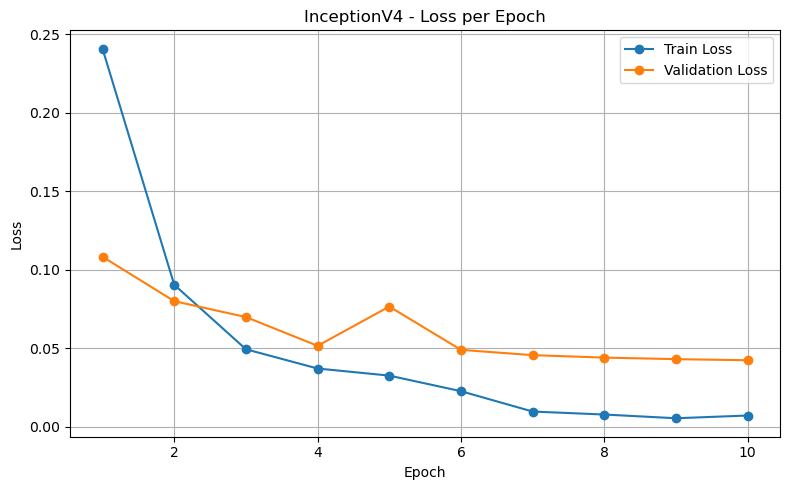

In [18]:
# ========== 11. Plotting ==========
epochs = range(1, len(train_accuracies) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_accuracies, 'o-', label='Train Accuracy')
plt.plot(epochs, val_accuracies, 'o-', label='Validation Accuracy')
plt.title('InceptionV4 - Accuracy per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("inceptionv4_accuracy_curve.png")
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_losses, 'o-', label='Train Loss')
plt.plot(epochs, val_losses, 'o-', label='Validation Loss')
plt.title('InceptionV4 - Loss per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("inceptionv4_loss_curve.png")
plt.show()

In [19]:
# ========== 12. Classification Report ==========
print("\n Classification Report:")
print(classification_report(all_labels, all_preds, target_names=full_dataset.classes))


 Classification Report:
              precision    recall  f1-score   support

      glioma       0.99      0.99      0.99       386
  meningioma       0.98      0.97      0.97       384
     notumor       0.99      1.00      0.99       498
   pituitary       0.99      0.99      0.99       446

    accuracy                           0.99      1714
   macro avg       0.99      0.99      0.99      1714
weighted avg       0.99      0.99      0.99      1714



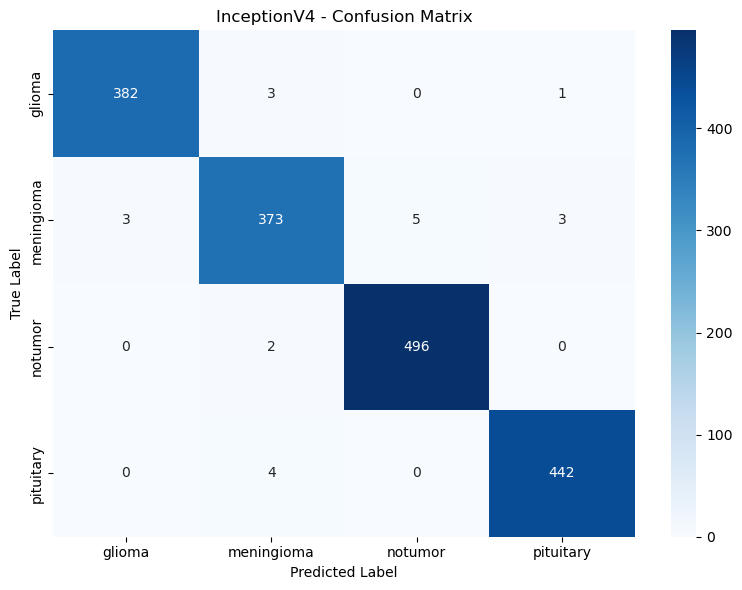

In [22]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Generate confusion matrix
cm = confusion_matrix(all_labels, all_preds)

# Class names from your dataset
class_names = full_dataset.classes

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title("InceptionV4 - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.savefig("inceptionv4_confusion_matrix.png")
plt.show()



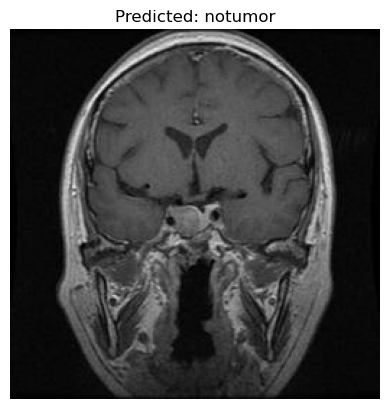

In [27]:
from PIL import Image
import torchvision.transforms as transforms
import torch
import matplotlib.pyplot as plt

# Define the transform (same as training)
predict_transform = transforms.Compose([
    transforms.Resize((299, 299)),  # InceptionV4 standard input size
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

# Prediction function
def predict_image(image_path, model, class_names):
    model.eval()
    
    # Load and transform the image
    image = Image.open(image_path).convert('RGB')
    input_tensor = predict_transform(image).unsqueeze(0).to(device)
    
    # Forward pass
    with torch.no_grad():
        output = model(input_tensor)
        _, predicted = torch.max(output, 1)
    
    # Display the image
    plt.imshow(image)
    plt.title(f"Predicted: {class_names[predicted.item()]}")
    plt.axis('off')
    plt.show()

# Example usage
test_image_path = r"C:\Users\STUDENT\Downloads\brainmri\archive\Testing_256x256\pituitary\Te-pi_0239.jpg"  # notumor
#test_image_path = r"C:\Users\STUDENT\Downloads\brainmri\archive\Testing_256x256\notumor\Te-no_0238.jpg"  # notumor
#test_image_path = r"C:\Users\STUDENT\Downloads\brain_menin.webp"  # menin


predict_image(test_image_path, model, class_names)


In [34]:
test_path = r"C:\Users\STUDENT\Downloads\brainmri\archive\Testing_256x256"

test_transform = transforms.Compose([
    transforms.Resize((299, 299)),  # for InceptionV4
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

test_dataset = datasets.ImageFolder(test_path, transform=test_transform)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

class_names = test_dataset.classes


In [38]:
import matplotlib.pyplot as plt
import numpy as np
import torch

# Unnormalize helper (for [0.5]*3 normalization)
def unnormalize(img_tensor):
    mean = torch.tensor([0.5, 0.5, 0.5])
    std = torch.tensor([0.5, 0.5, 0.5])
    img_tensor = img_tensor * std[:, None, None] + mean[:, None, None]
    return img_tensor

def show_classwise_predictions(model, dataset, class_names, device, images_per_class=4):
    """
    Displays `images_per_class` predictions for each class.
    Expects the dataset (not DataLoader).
    """
    model.eval()
    shown_classes = set()

    with torch.no_grad():
        for class_idx in range(len(class_names)):
            # Filter samples for this class
            class_samples = [sample for sample in dataset if sample[1] == class_idx]
            if len(class_samples) < images_per_class:
                continue

            plt.figure(figsize=(12, 4))
            for i in range(images_per_class):
                img, label = class_samples[i]
                input_tensor = img.unsqueeze(0).to(device)
                output = model(input_tensor)
                pred = torch.argmax(output, dim=1).item()

                img = unnormalize(img).permute(1, 2, 0).numpy()
                img = np.clip(img, 0, 1)

                plt.subplot(1, images_per_class, i + 1)
                plt.imshow(img)
                plt.title(f"Pred: {class_names[pred]}\nTrue: {class_names[label]}", fontsize=10)
                plt.axis('off')

            plt.suptitle(f"Class: {class_names[class_idx]}", fontsize=14)
            plt.tight_layout()
            plt.show()


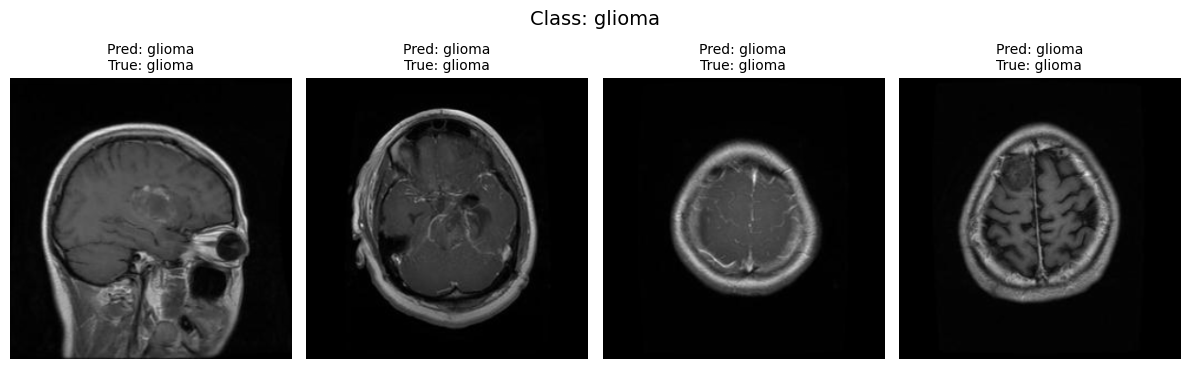

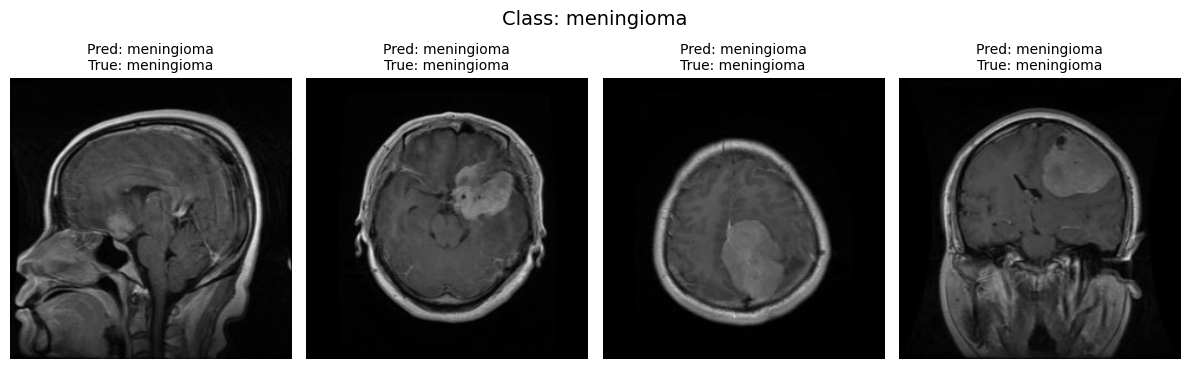

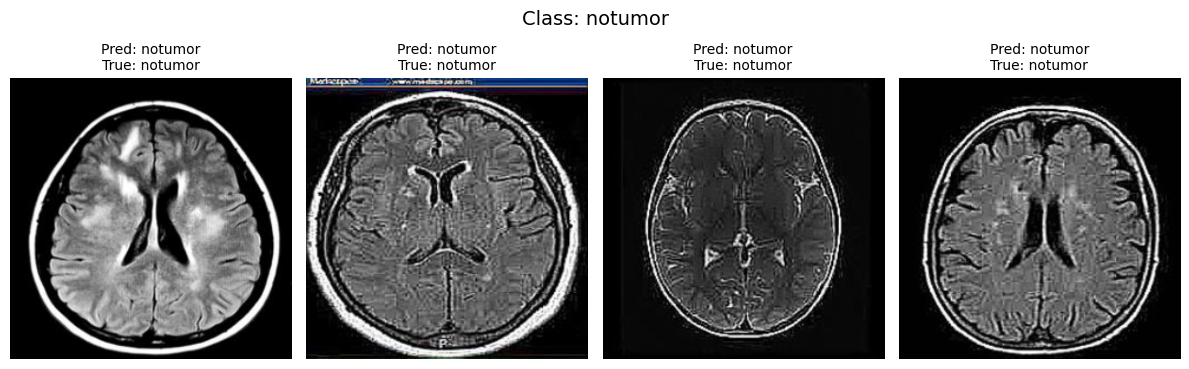

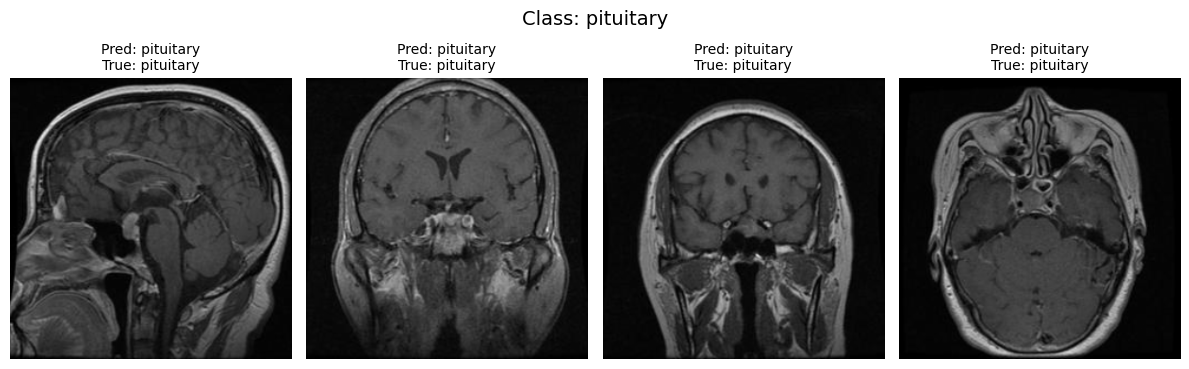

In [39]:
# Assuming `val_dataset` or `test_dataset` exists and uses test_transform
show_classwise_predictions(model, val_dataset, class_names=full_dataset.classes, device=device, images_per_class=4)